# 22. A daily M4 project: guarded selection, resume and cost

**Goal and requirements.** Run a small forecasting project on real daily M4 series, from drawing the sample to the evaluation: prepare the temporal validation, compare AutoHybTS's guarded selection with choosing the lowest error, log each series to an SQLite database (which lets an interrupted project resume without redoing what finished) and measure the cost. The project uses only the **official training data**: its last 14 points are sealed for the internal evaluation, and the official test is not downloaded. `stats` and `plot` extras; the first run downloads the daily M4 training data.

In [1]:
import hashlib
import json
import subprocess
import sys
import time
import warnings
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import autohybts
from autohybts import AutoHybridExperiment, ExperimentStore, load_model, read_manifest, save_model
from autohybts.benchmarks import benchmark_cases
from autohybts.domain.identity import stable_hash
from autohybts.exceptions import ConfigurationError
from autohybts.persistence.manifest import environment, json_safe, source_fingerprint

print("AutoHybTS", autohybts.__version__)

AutoHybTS 1.0.0rc4


## 1. Data and protocol

The sample is 3 series drawn with seed 0 out of the 4227 daily M4 series; nobody picks them by hand. Of each we use only the official training data, cut to the last 730 days to control the cost. The horizon is daily M4's, 14 steps, forecast at once (protocol A); the MASE scaling period is M4's (1).

In [2]:
cases = list(benchmark_cases("m4", "daily", 3, 0, development_only=True, development_tail=730))
H = cases[0].horizon
pd.DataFrame(
    [
        {
            "series": case.series_id,
            "official_train": case.source["original_train_length"],
            "points_used": len(case.values),
            "start": case.values.index[0].date(),
            "end": case.values.index[-1].date(),
        }
        for case in cases
    ]
).set_index("series")
assert all(case.source["official_test_accessed"] is False for case in cases)

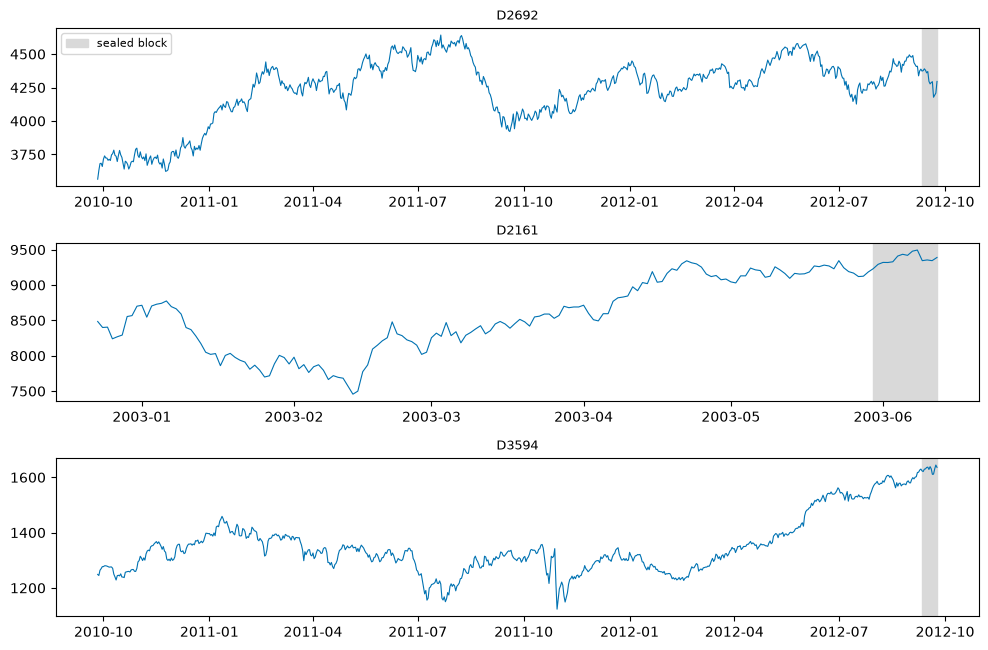

In [3]:
fig, axes = plt.subplots(len(cases), 1, figsize=(10, 2.2 * len(cases)), squeeze=False)
for ax, case in zip(axes.flat, cases, strict=True):
    ax.plot(case.values.index, case.values.to_numpy(), linewidth=0.8, color="#0072B2")
    ax.axvspan(case.values.index[-H], case.values.index[-1], color="0.85", label="sealed block")
    ax.set_title(case.series_id, fontsize=9)
axes.flat[0].legend(fontsize=8)
fig.tight_layout()
plt.show()

## 2. Causal exploration

`fit` searches nothing: it validates the series, seals the last 14 points and fixes the `V_search` and `V_select` origins. The table shows how many origins each series allows per layer (the acceptance rule was calibrated with 7) and how many differences ADF and KPSS together ask for on the development stretch.

In [4]:
SETTINGS = {
    "fh": H,
    "test_size": H,
    "seasonal_period": cases[0].seasonal_period,
    "session_id": 42,
    "budget": "small",
    "base_models": ["naive", "random_walk_drift", "linear", "exponential_smoothing"],
    "correctors": ["linear", "knn"],
}
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    experiments = {
        case.series_id: AutoHybridExperiment(**SETTINGS).fit(case.values) for case in cases
    }
for message, count in Counter(str(item.message) for item in caught).items():
    print(f"WARNING ({count}): {message}")
pd.DataFrame(
    {
        sid: {
            "development_points": len(exp.history_),
            "origins_per_layer": exp.fold_,
            "suggested_differences": int(exp.stationarity_report()["d_consensus"].iloc[0]),
        }
        for sid, exp in experiments.items()
    }
).T

WARNING (1): fold='auto': o histórico comporta 4 origem(ns) por camada, menos que as 7 da calibração da regra de aceite; com menos unidades a regra aceita estruturas espúrias com mais frequência.


,development_points,origins_per_layer,suggested_differences
D2692,716,7,1
D2161,158,4,1
D3594,716,7,1


## 3. Controls and proposed models

The same search (persistence, random walk with drift, linear regression, exponential smoothing and linear and KNN residual corrections) feeds three choices:

- **guarded selection** (`compare_models().best`): accepts complexity only when it passes the acceptance rule;
- **lowest error**: the finalist with the lowest MASE on `V_select`, without a threshold;
- **persistence**: the simplest control.

Each series becomes a run in `artifacts/m4_project/m4.db`. The directory is preserved: rerunning the notebook reuses compatible cases. Data, settings, environment and library sources enter the identity; changes require another directory. The workflow revision is explicit in the schema. Run only one writer process per directory.

A case is recorded only after search, evaluation of distinct choices and model persistence. These artifacts are created by this execution, so loading explicitly declares trust. Forecast equivalence is checked before recording. If interrupted before that transaction, the case is repeated; previously committed cases remain intact.

In [5]:
folder = Path("artifacts/m4_project")
store = ExperimentStore(folder / "m4.db")
identity = {
    "schema": "m4-project/3",
    "settings": SETTINGS,
    "data": {
        case.series_id: hashlib.sha256(
            pd.util.hash_pandas_object(case.values, index=True).to_numpy().tobytes()
        ).hexdigest()
        for case in cases
    },
    "source": source_fingerprint(),
    "environment": {key: value for key, value in environment().items() if key != "git_commit"},
}
project_id = stable_hash(json_safe(identity))


def verify_saved(tags):
    """Check saved models against forecasts already in SQLite, without reading targets again."""
    predictions = store.query("SELECT model_id, timestamp, y_pred FROM predictions")
    for choice in {item["model_id"]: item for item in tags["choices"].values()}.values():
        model = load_model(folder / choice["artifact"], trusted=True, sha256=choice["sha256"])
        recorded = predictions[predictions.model_id == choice["model_id"]].sort_values("timestamp")
        if len(recorded) != H:
            raise ConfigurationError("Incomplete saved forecasts; restore the project artifacts.")
        np.testing.assert_allclose(model.predict(H).y_pred, recorded.y_pred, rtol=1e-12, atol=1e-12)


def run_project():
    """Persist evaluated cases and reuse compatible complete results."""
    saved = (
        store.query("SELECT name, tags FROM runs")
        if store.path.is_file()
        else pd.DataFrame(columns=["name", "tags"])
    )
    completed = {}
    for row in saved.itertuples():
        tags = json.loads(row.tags)
        if tags.get("project_id") != project_id:
            raise ConfigurationError("Incompatible project: use a different output directory.")
        verify_saved(tags)
        completed[row.name] = tags
    new = []
    for sid, exp in experiments.items():
        if sid in completed:
            continue
        started = time.perf_counter()
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter("always")
            result = exp.compare_models()
            search_seconds = time.perf_counter() - started
            lowest_id = result.selection_leaderboard.MASE.idxmin()
            lowest = next(
                r.candidate for r in result.selection.finalists if r.candidate_id == lowest_id
            )
            picks = {
                "guarded": result.best,
                "lowest_error": lowest,
                "persistence": exp.create_model("naive").candidate,
            }
            models, choices = {}, {}
            for label, spec in picks.items():
                if spec.candidate_id not in models:
                    model = exp.finalize_model(spec)
                    exp.evaluate_external(model)
                    relative = Path("models") / sid / model.model_id
                    save_model(model, folder / relative)
                    restored = load_model(folder / relative, trusted=True)
                    pd.testing.assert_frame_equal(model.predict(H), restored.predict(H))
                    models[spec.candidate_id] = model
                model = models[spec.candidate_id]
                relative = Path("models") / sid / model.model_id
                choices[label] = {
                    "model_id": model.model_id,
                    "artifact": relative.as_posix(),
                    "sha256": read_manifest(folder / relative)["payload"]["sha256"],
                }
        messages = Counter(str(item.message) for item in caught)
        for message, count in messages.items():
            print(f"WARNING ({count}): {message}")
        tags = {
            "project_id": project_id,
            "identity": identity,
            "choices": choices,
            "search_seconds": search_seconds,
            "case_seconds": time.perf_counter() - started,
            "warnings": dict(messages),
        }
        store.log(exp, name=sid, tags=tags, models=list(models.values()), values=True)
        verify_saved(tags)
        new.append(sid)
    return new

## 4. Search and selection

The first call runs only unfinished series. The second checks that records stay unchanged. Rerunning after a kernel restart calls the same function, checks identity and artifacts and reuses complete cases. Later steps read persisted tables without depending on search-result objects. Warnings are displayed and recorded rather than discarded.

In [6]:
print("New cases:", run_project())
before = store.query("SELECT run_id, logged_utc FROM runs ORDER BY run_id")
assert run_project() == []
pd.testing.assert_frame_equal(
    before, store.query("SELECT run_id, logged_utc FROM runs ORDER BY run_id")
)
print("Resume: no new cases; database records unchanged.")
saved_runs = store.query("SELECT name, tags FROM runs ORDER BY name")
pd.DataFrame(
    [
        {
            "series": row.name,
            **{key: json.loads(row.tags)[key] for key in ("search_seconds", "case_seconds")},
        }
        for row in saved_runs.itertuples()
    ]
).set_index("series").round(2)

New cases: ['D2692', 'D2161', 'D3594']
Resume: no new cases; database records unchanged.


,search_seconds,case_seconds
series,,
D2161,3.26,3.48
D2692,23.79,24.17
D3594,23.07,23.22


## 5. Results and plots

The database answers who won in each series and why: each challenger compared with the current champion, with median gain, win rate and reason.

In [7]:
store.query(
    """
    SELECT r.name AS series, d.family, d.challenger_label AS challenger, d.accepted AS accepted,
           ROUND(d.median_gain, 3) AS median_gain, ROUND(d.win_rate, 2) AS win_rate,
           d.reason_codes AS reasons
    FROM decisions d JOIN runs r USING (run_id)
    ORDER BY r.name, d.step
    """
)

,series,family,challenger,accepted,median_gain,win_rate,reasons
0,D2161,linear,linear(lags=7),0,-0.639,0.00,"[""median_gain_below_threshold"", ""win_rate_belo..."
1,D2161,residual,"naive + linear [w=7, alpha=0.5, historical_oof...",0,0.037,1.00,"[""median_gain_below_threshold""]"
2,D2692,linear,linear(lags=7),0,0.064,0.57,"[""win_rate_below_threshold""]"
3,D2692,residual,"random_walk_drift + linear [w=7, alpha=0.5, hi...",0,-0.008,0.29,"[""median_gain_below_threshold"", ""win_rate_belo..."
4,D3594,linear,linear(lags=7),0,-0.184,0.29,"[""median_gain_below_threshold"", ""win_rate_belo..."
5,D3594,residual,"random_walk_drift + linear [w=7, alpha=1.0, hi...",0,-0.002,0.43,"[""median_gain_below_threshold"", ""win_rate_belo..."


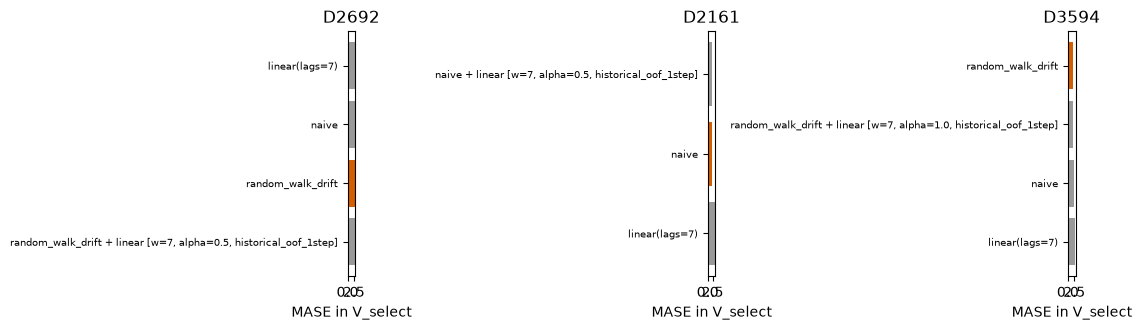

In [8]:
board = store.query(
    """
    SELECT r.name AS series, c.label, m.value AS MASE, e.is_champion
    FROM metrics m JOIN runs r USING (run_id)
    JOIN candidates c USING (run_id, candidate_id)
    JOIN evaluations e USING (run_id, candidate_id, layer)
    WHERE m.layer = 'select' AND m.metric = 'MASE'
    ORDER BY r.name, m.value
    """
)
fig, axes = plt.subplots(1, len(cases), figsize=(11, 3.4), squeeze=False)
for ax, case in zip(axes.flat, cases, strict=True):
    part = board[board.series == case.series_id]
    ax.barh(
        part.label, part.MASE, color=["#D55E00" if value else "0.6" for value in part.is_champion]
    )
    ax.invert_yaxis()
    ax.set(title=case.series_id, xlabel="MASE in V_select")
    ax.tick_params(axis="y", labelsize=7)
fig.tight_layout()
plt.show()

## 6. Diagnostics and limits

A short series allows fewer origins than the acceptance rule's calibrated 7; with fewer units the rule accepts spurious structures more often, and the experiment warns. Three series, one seed and the `small` budget size the project, but do not support conclusions about the whole M4.

In [9]:
store.query(
    """
    SELECT r.name AS series, r.n_origins AS origins_both_layers, COUNT(l.seq) AS proposals,
           SUM(l.status = 'EVALUATED') AS evaluated, ROUND(SUM(l.seconds), 1) AS search_seconds
    FROM runs r JOIN ledger l USING (run_id)
    GROUP BY r.name ORDER BY r.name
    """
)

,series,origins_both_layers,proposals,evaluated,search_seconds
0,D2161,8,32,17,2.9
1,D2692,14,32,17,22.7
2,D3594,14,32,17,22.1


## 7. Internal evaluation and cost

Each distinct choice was refitted and evaluated once on the internal block during `run_project`, before the final case record. Here we read metrics and forecasts from SQLite without reopening that block. The table is exported as CSV. `search_seconds` measures search/selection; `case_seconds` also includes refitting, evaluation and persistence. Shared costs are not summed across choices.

In [10]:
rows, paths = [], {}
external = store.query(
    "SELECT run_id, model_id, value FROM external WHERE metric = 'MASE' AND series_id IS NOT NULL"
)
predictions = store.query(
    "SELECT model_id, timestamp, y_pred, y_true FROM predictions ORDER BY timestamp"
)
for run in store.query("SELECT run_id, name, tags FROM runs ORDER BY name").itertuples():
    for label, choice in json.loads(run.tags)["choices"].items():
        score = external[
            (external.run_id == run.run_id) & (external.model_id == choice["model_id"])
        ]
        if len(score) != 1:
            raise ConfigurationError("Missing or ambiguous saved evaluation.")
        rows.append({"series": run.name, "choice": label, "MASE": score.value.iloc[0]})
        path = predictions[predictions.model_id == choice["model_id"]].copy()
        path["timestamp"] = pd.to_datetime(path.timestamp)
        paths[run.name, label] = path.set_index("timestamp")
internal = pd.DataFrame(rows)
internal.to_csv(folder / "internal_metrics.csv", index=False)
internal.pivot(index="series", columns="choice", values="MASE").round(3)

choice,guarded,lowest_error,persistence
series,,,
D2161,2.591,2.509,2.591
D2692,3.366,2.724,3.058
D3594,0.836,0.836,0.791


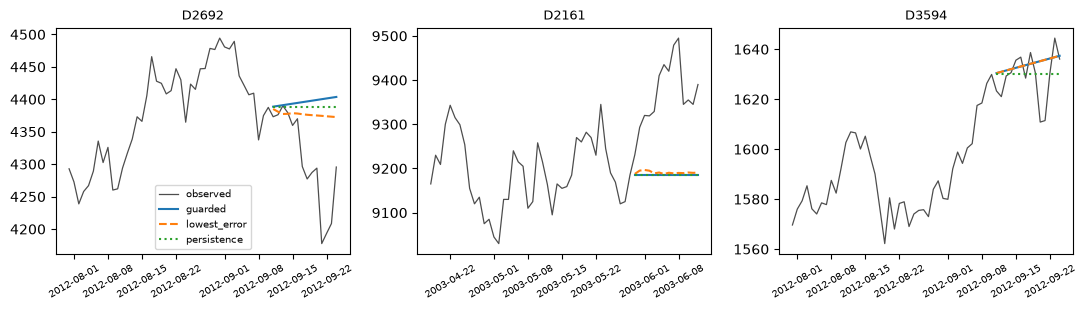

In [11]:
fig, axes = plt.subplots(1, len(cases), figsize=(11, 3.2), squeeze=False)
for ax, case in zip(axes.flat, cases, strict=True):
    sid = case.series_id
    recent = case.values.iloc[-4 * H :]
    ax.plot(recent.index, recent.to_numpy(), color="0.3", linewidth=0.9, label="observed")
    for label, style in (("guarded", "-"), ("lowest_error", "--"), ("persistence", ":")):
        table = paths[sid, label]
        ax.plot(table.index, table["y_pred"], linestyle=style, label=label)
    ax.set_title(sid, fontsize=9)
    ax.tick_params(axis="x", labelrotation=30, labelsize=7)
axes.flat[0].legend(fontsize=7)
fig.tight_layout()
plt.show()

### Independent-process verification

A new interpreter opens the database and loads the saved models without session objects. Forecasts are compared with stored predictions without reading targets again.

In [12]:
verification = """
import json
import sys
from pathlib import Path
import numpy as np
from autohybts import ExperimentStore, load_model
folder = Path(sys.argv[1])
store = ExperimentStore(folder / 'm4.db')
runs = store.query('SELECT tags FROM runs')
predictions = store.query('SELECT model_id, timestamp, y_pred FROM predictions ORDER BY timestamp')
checked = set()
for row in runs.itertuples():
    for choice in json.loads(row.tags)['choices'].values():
        if choice['model_id'] in checked:
            continue
        model = load_model(folder / choice['artifact'], trusted=True, sha256=choice['sha256'])
        recorded = predictions[predictions.model_id == choice['model_id']]
        np.testing.assert_allclose(
            model.predict(len(recorded)).y_pred, recorded.y_pred, rtol=1e-12, atol=1e-12
        )
        checked.add(choice['model_id'])
print(f'Independent process: {len(runs)} cases and {len(checked)} models verified.')
"""
verified = subprocess.run(
    [sys.executable, "-c", verification, str(folder.resolve())],
    check=True,
    capture_output=True,
    text=True,
)
print(verified.stdout.strip())

Independent process: 3 cases and 7 models verified.


## 8. Reading

- **Data.** The draw brought D2692, D2161 and D3594. D2161 has only 172 days of official training data: it allows 4 origins per layer, fewer than the calibrated 7, and the experiment warned. In all three series, ADF and KPSS ask for one difference.
- **Guarded selection.** It kept a standalone model in all three: persistence in D2161 and random walk with drift in the other two. No challenger passed the acceptance rule, for different reasons. In D2161, the persistence + linear corrector hybrid won on all 4 units, but with a median gain of 3.7 %, below 5 %. In D2692, linear regression had a 6.4 % gain but only 57 % wins, below 60 %.
- **Lowest error.** It would choose that hybrid in D2161 and linear regression in D2692. On the sealed 14-day block, those choices had a lower MASE than the guarded selection: 2.51 against 2.59 and 2.72 against 3.37. In D3594 both chose the same model, and persistence was the best (0.79 against 0.84).
- **How to read this.** On this sample, the rule's caution did not pay off: the candidates it refused were close to the threshold and did well on the internal block. But each series had a single 14-day window, and three series do not support a comparison. The rule was calibrated to rarely err by excess complexity over many series, not to win on each one. A study with more series and seeds is what decides whether it is too conservative on daily M4.
- **Resume and cost.** Search/selection totaled 50.1 s and complete cases, including refitting, evaluation and persistence, 50.9 s in this execution. The second call created no cases or record changes. Another process loaded the models and reproduced stored forecasts; rerunning the notebook reconstructs the tables from SQLite. Timings depend on hardware and caches. A case interrupted before its final transaction is repeated; other cases are preserved.